Training data: (60000, 28, 28)
Test data: (10000, 28, 28)
CNN training data: (60000, 28, 28, 1)
CNN test data: (10000, 28, 28, 1)


CNN WITH DROPOUT - MODEL SUMMARY
Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_1 (Conv2D)            (None, 26, 26, 32)        320       
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 13, 13, 32)        0         
_________________________________________________________________
conv2d_2 (Conv2D)            (None, 11, 11, 64)        18496     
_________________________________________________________________
max_pooling2d_2 (MaxPooling2 (None, 5, 5, 64)          0         
_________________________________________________________________
flatten (Flatten)            (None, 1600)              0         
_________________________________________________________________
dense_128 (Dense)    

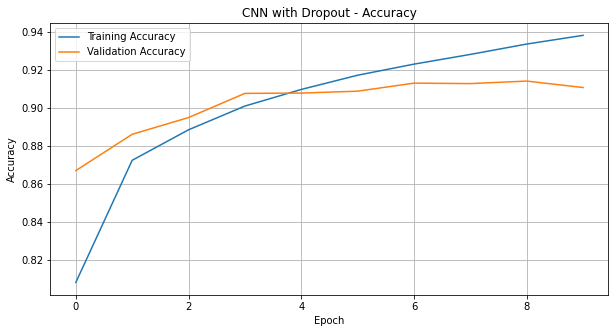

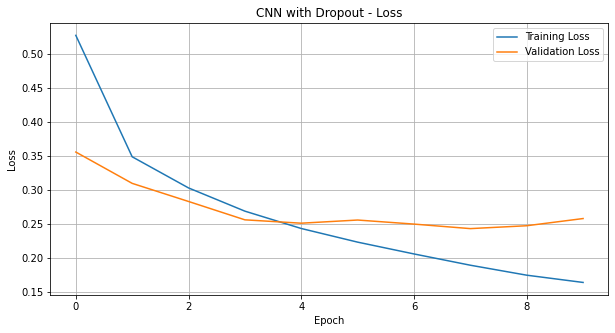

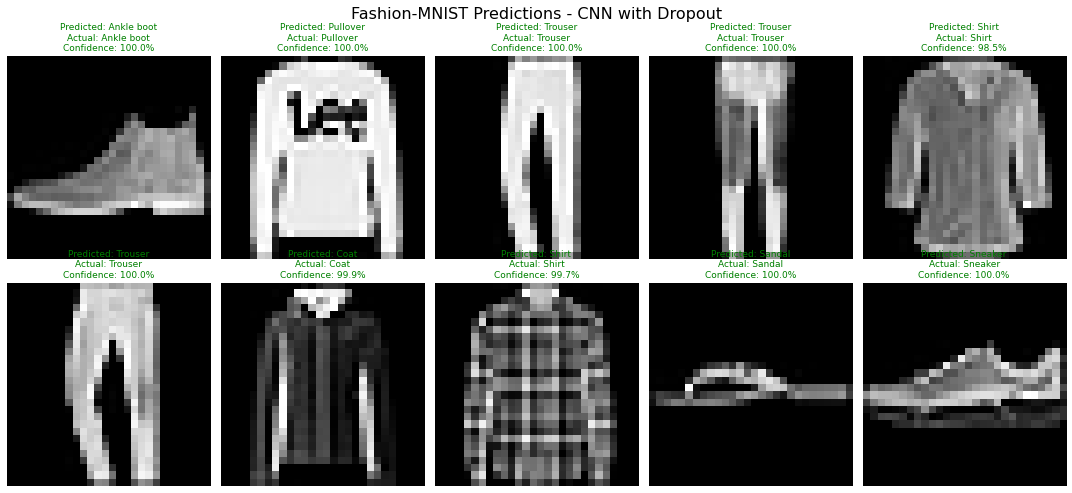

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dense,
    Flatten,
    Dropout
)


(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training data:", x_train.shape)
print("Test data:", x_test.shape)


class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]


x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0


x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("CNN training data:", x_train.shape)
print("CNN test data:", x_test.shape)


model = Sequential([

    Conv2D(32,(3, 3),activation='relu',input_shape=(28, 28, 1),name="conv2d_1"),

    MaxPooling2D((2, 2),name="max_pooling2d_1"),

    Conv2D(64,(3, 3),activation='relu',name="conv2d_2"),

    MaxPooling2D((2, 2),name="max_pooling2d_2"),

    Flatten(name="flatten"),

    Dense(128,activation='relu',name="dense_128"),

    Dropout(0.3,name="dropout"),

    Dense(10,activation='softmax',name="output")
])


model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


print("\n")
print("=" * 70)
print("CNN WITH DROPOUT - MODEL SUMMARY")
print("=" * 70)

model.summary()


print("\n")
print("=" * 70)
print("TRAINING MODEL")
print("=" * 70)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    validation_split=0.2,
    batch_size=32,
    verbose=1
)



test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("\n")
print("=" * 70)
print("MODEL PERFORMANCE")
print("=" * 70)

print(f"Test Accuracy : {test_acc:.4f}")
print(f"Test Loss     : {test_loss:.4f}")



plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN with Dropout - Accuracy")

plt.legend()
plt.grid()

plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN with Dropout - Loss")

plt.legend()
plt.grid()

plt.show()



predictions = model.predict(
    x_test[:10],
    verbose=0
)


plt.figure(figsize=(15, 7))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    # Display image
    plt.imshow(
        x_test[i].reshape(28, 28),
        cmap='gray'
    )

    predicted_class = np.argmax(predictions[i])

    actual_class = y_test[i]

    confidence = np.max(predictions[i]) * 100


    color = (
        'green'
        if predicted_class == actual_class
        else 'red'
    )

    plt.title(
        f"Predicted: {class_names[predicted_class]}\n"
        f"Actual: {class_names[actual_class]}\n"
        f"Confidence: {confidence:.1f}%",
        color=color,
        fontsize=9
    )

    plt.axis('off')


plt.suptitle(
    "Fashion-MNIST Predictions - CNN with Dropout",
    fontsize=16
)

plt.tight_layout()
plt.show()
